In [1]:
#Imports
import skimage
import scipy
from matplotlib import pyplot as plt
import numpy as np
from skimage.filters import gaussian
import os

from skimage.color import rgb2gray
from skimage import img_as_float
from skimage import exposure
from skimage.feature import canny
from skimage import io, color
from skimage.transform import hough_line, hough_line_peaks



os.getcwd()

'/Users/nistha/Downloads/second year/CVi_edge_Detector_2439590'

Preprocess a HEp-2 cell image:
    - load
    - convert to float
    - grayscale
    - invert (white background, dark cells) as ground truth images
    - Gaussian smoothing (denoising)
    - CLAHE contrast enhancement

    Returns:
        preprocessed_img  


In [2]:
def preprocess_image(path, sigma=1.0, clip_limit=0.01, img_name="", show_plots=False):
    # Load (RGB or grayscale)
    img_rgb = skimage.io.imread(path)

    # Convert to float [0,1]
    img_float = img_as_float(img_rgb)

    # Convert to grayscale
    img_gray = rgb2gray(img_float)

    # Invert (white background, dark cells)
    img_inverted = 1.0 - img_gray

    # Gaussian smoothing
    img_smooth = gaussian(img_inverted, sigma=sigma)

    # Contrast enhancement (CLAHE)
    preprocessed_img = exposure.equalize_adapthist(img_smooth, clip_limit=clip_limit)

    if show_plots:
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 3, 1)
        plt.imshow(img_gray, cmap="gray")
        plt.title(f"{img_name} – Grayscale")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(img_inverted, cmap="gray")
        plt.title(f"{img_name} – Inverted")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(preprocessed_img, cmap="gray")
        plt.title(f"{img_name} – Preprocessed (σ={sigma})")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

    return preprocessed_img

In [3]:
sobel_x = np.array(
    [[1,0,-1],
     [2,0,-2],
     [1,0,-1]])

sobel_y = np.array(
    [[1,2,1],
     [0,0,0],
     [-1,-2,-1]])

# Prewitt X: vertical edges (left↔right changes)
prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])

# Prewitt Y: horizontal edges (up↔down changes)
prewitt_y = np.array([[-1, -1, -1],
                      [ 0,  0,  0],
                      [ 1,  1,  1]])


# The standard 4-neighbour Laplacian
laplacian_kernel = np.array([[0,  1, 0],
                             [1, -4, 1],
                             [0,  1, 0]])

# 8-neighbour Laplacian
laplacian_kernel_8 = np.array([[1,  1, 1],
                               [1, -8, 1],
                               [1,  1, 1]], dtype=float)


We need a function for binary edges to get white background and black edges (to make it similar to ground truth images). The function will contain 
    mag_norm: normalised magnitude/response in [0,1]
    threshold: scalar in [0,1]
    returns: float image, 0 = black (edges), 1 = white (background)

In [4]:
# function for binary edges to get white background and black edges (to make it similar to ground truth images)
def binary_edges_from_mag(mag_norm, threshold):
    
    edges = mag_norm > threshold      # True where edge
    edges_bw = np.where(edges, 0.0, 1.0)
    return edges_bw



We also need a function to load ground-truth edge image and convert to a boolean edge mask.
    Returns:
      gt_img      : float image [0,1]
      gt_edges    : boolean mask, True where edge

In [5]:
def load_gt_edges(gt_path, thresh=0.5):

    gt_img = skimage.io.imread(gt_path)
    gt_img = img_as_float(gt_img)  # [0,1]

    # If RGB, convert to grayscale by averaging channels
    if gt_img.ndim == 3:
        gt_gray = gt_img.mean(axis=2)  # (H, W, 3) -> (H, W)
    else:
        gt_gray = gt_img

    # Binary edge mask: dark pixels = edges
    gt_edges = gt_gray < thresh

    return gt_gray, gt_edges

We need a function to Apply Sobel to preprocessed image.
    - computes Gx, Gy, magnitude
    - normalises to [0,1]
    - for each threshold in `thresholds`, makes a binary edge image
      (white background, black edges) and plots it.

    Returns:
      sobel_mag_norm (normalised Sobel magnitude, for further use)
    

In [6]:
def sobel_detector(preprocessed_img, img_name, thresholds, show_plots=True):
    
    # Convolve with Sobel kernels
    Gx = scipy.signal.convolve2d(preprocessed_img, sobel_x, mode="same", boundary="symm")
    Gy = scipy.signal.convolve2d(preprocessed_img, sobel_y, mode="same", boundary="symm")

    # Gradient magnitude
    magnitude = np.hypot(Gx, Gy)
    sobel_mag_norm = magnitude / (magnitude.max() + 1e-8)

    if show_plots:
        # Show Gx, Gy, magnitude
        plt.figure(figsize=(15, 4))
        plt.subplot(1, 3, 1)
        plt.imshow(Gx, cmap="gray")
        plt.title(f"{img_name} – Sobel Gx")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(Gy, cmap="gray")
        plt.title(f"{img_name} – Sobel Gy")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(sobel_mag_norm, cmap="gray")
        plt.title(f"{img_name} – Sobel magnitude")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

        # Threshold tests
        plt.figure(figsize=(4 * len(thresholds), 4))
        for i, t in enumerate(thresholds, 1):
            edges_bw = binary_edges_from_mag(sobel_mag_norm, t)
            plt.subplot(1, len(thresholds), i)
            plt.imshow(edges_bw, cmap="gray", vmin=0, vmax=1)
            plt.title(f"Sobel {img_name}\nT = {t}")
            plt.axis("off")

        plt.tight_layout()
        plt.show()

    return sobel_mag_norm

A function to apply Prewitt to preprocessed image.
    Returns:
      prewitt_mag_norm

In [7]:
def prewitt_detector(preprocessed_img, img_name, thresholds, show_plots=True):

    Px = scipy.signal.convolve2d(preprocessed_img, prewitt_x, mode="same", boundary="symm")
    Py = scipy.signal.convolve2d(preprocessed_img, prewitt_y, mode="same", boundary="symm")

    prewitt_mag = np.hypot(Px, Py)
    prewitt_mag_norm = prewitt_mag / (prewitt_mag.max() + 1e-8)

    if show_plots:
        # Show Px, Py, magnitude
        plt.figure(figsize=(15, 4))
        plt.subplot(1, 3, 1)
        plt.imshow(Px, cmap="gray")
        plt.title(f"{img_name} – Prewitt Px")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(Py, cmap="gray")
        plt.title(f"{img_name} – Prewitt Py")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(prewitt_mag_norm, cmap="gray")
        plt.title(f"{img_name} – Prewitt magnitude")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

        # Threshold tests
        plt.figure(figsize=(4 * len(thresholds), 4))
        for i, t in enumerate(thresholds, 1):
            edges_bw = binary_edges_from_mag(prewitt_mag_norm, t)
            plt.subplot(1, len(thresholds), i)
            plt.imshow(edges_bw, cmap="gray", vmin=0, vmax=1)
            plt.title(f"Prewitt {img_name}\nT = {t}")
            plt.axis("off")

        plt.tight_layout()
        plt.show()

    return prewitt_mag_norm


   Function to apply Laplacian to preprocessed image.
    Returns:
      laplacian_norm

In [8]:
def laplacian_detector(preprocessed_img, img_name, thresholds, show_plots=True):

    L = scipy.signal.convolve2d(preprocessed_img, laplacian_kernel,
                                mode="same", boundary="symm")

    L_abs = np.abs(L)
    laplacian_norm = L_abs / (L_abs.max() + 1e-8)

    if show_plots:
        # Show raw + normalized
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 3, 1)
        plt.imshow(preprocessed_img, cmap="gray")
        plt.title(f"{img_name} – Preprocessed")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(L, cmap="gray")
        plt.title(f"{img_name} – Laplacian raw")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(laplacian_norm, cmap="gray")
        plt.title(f"{img_name} – |Laplacian| (norm)")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

        # Threshold tests
        plt.figure(figsize=(4 * len(thresholds), 4))
        for i, t in enumerate(thresholds, 1):
            edges_bw = binary_edges_from_mag(laplacian_norm, t)
            plt.subplot(1, len(thresholds), i)
            plt.imshow(edges_bw, cmap="gray", vmin=0, vmax=1)
            plt.title(f"Laplacian {img_name}\nT = {t}")
            plt.axis("off")

        plt.tight_layout()
        plt.show()

    return laplacian_norm

In [9]:
def compute_iou(gt_edges, pred_edges):
    # Jaccard Index (IoU) for edge pixels.
    # gt_edges, pred_edges: boolean arrays (True = edge).

    intersection = np.logical_and(gt_edges, pred_edges).sum()
    union        = np.logical_or(gt_edges,  pred_edges).sum()
    return intersection / (union + 1e-8)


def compute_dice(gt_edges, pred_edges):
    # Dice score (F1) for edge pixels.
    intersection = np.logical_and(gt_edges, pred_edges).sum()
    total_edges  = gt_edges.sum() + pred_edges.sum()
    return 2 * intersection / (total_edges + 1e-8)


def compute_accuracy(gt_edges, pred_edges):
    # Pixel-wise accuracy over whole image.
    correct = (gt_edges == pred_edges).sum()
    total   = gt_edges.size
    return correct / (total + 1e-8)

In [10]:
def bw_to_edge_mask(edges_bw, thresh=0.5):

    return edges_bw < thresh   # 0 → True, 1 → False

In [11]:
def find_best_threshold(mag_norm, gt_edges, thresholds, method_name="", img_name=""):
    
    all_results = []
    best_t = None
    best_iou = -1.0

    for t in thresholds:
        # 1) Build edge image for this threshold (0 = edge, 1 = bg)
        edges_bw = binary_edges_from_mag(mag_norm, t)
        # 2) Convert to boolean mask
        pred_edges = bw_to_edge_mask(edges_bw)

        # 3) Metrics
        iou  = compute_iou(gt_edges, pred_edges)
        dice = compute_dice(gt_edges, pred_edges)
        acc  = compute_accuracy(gt_edges, pred_edges)

        all_results.append({
            "threshold": t,
            "IoU": iou,
            "Dice": dice,
            "Accuracy": acc
        })

        # Track best by IoU (you could also use Dice)
        if iou > best_iou:
            best_iou = iou
            best_t   = t

    # Print a small summary
    # print(f"\n=== {method_name} on {img_name} ===")
    # for r in all_results:
        # print(f"T={r['threshold']:.3f} | IoU={r['IoU']:.4f} | Dice={r['Dice']:.4f} | Acc={r['Accuracy']:.4f}")
    print(f"--> Best {method_name} threshold for {img_name}: T={best_t:.3f} (IoU={best_iou:.4f})")

    return best_t, all_results

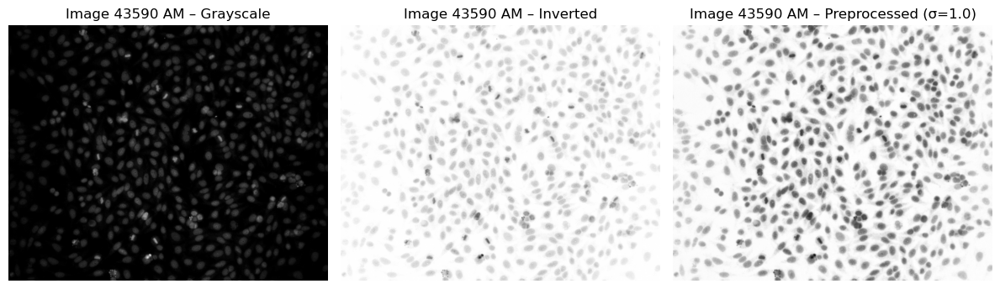

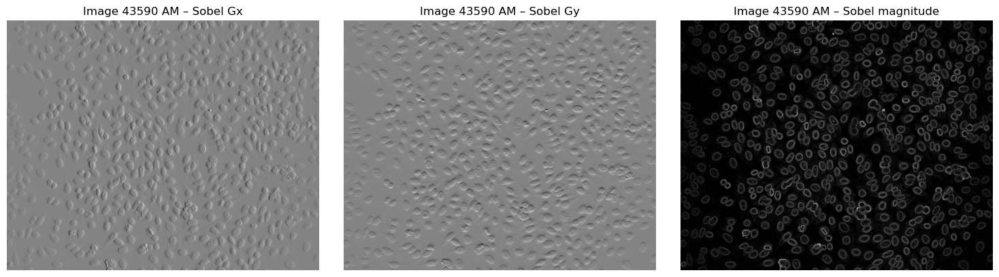

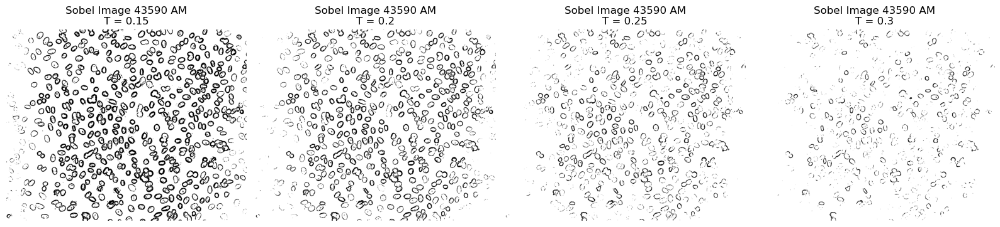

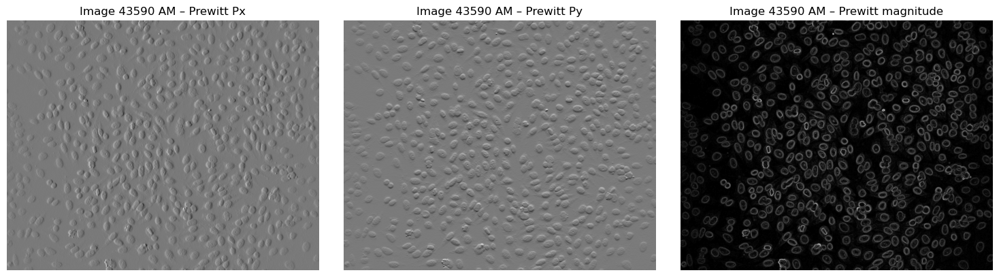

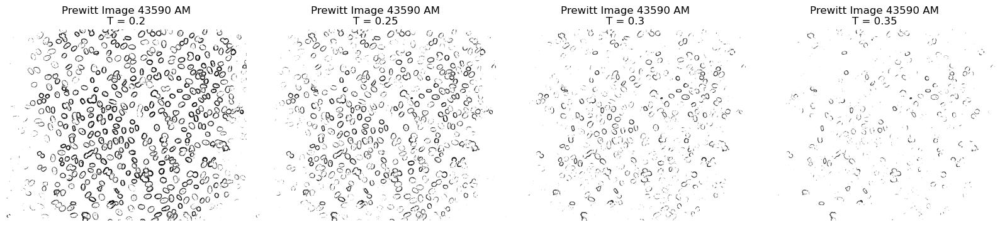

...

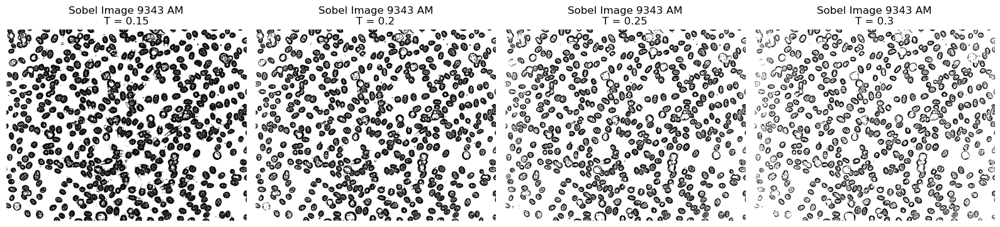

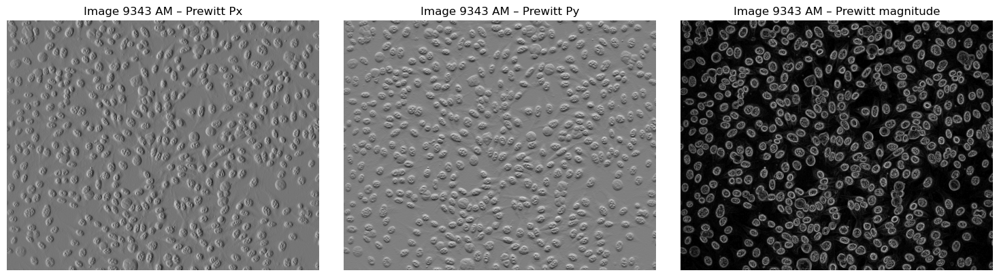

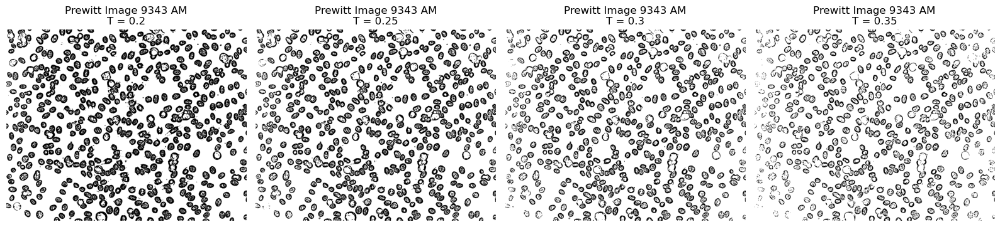

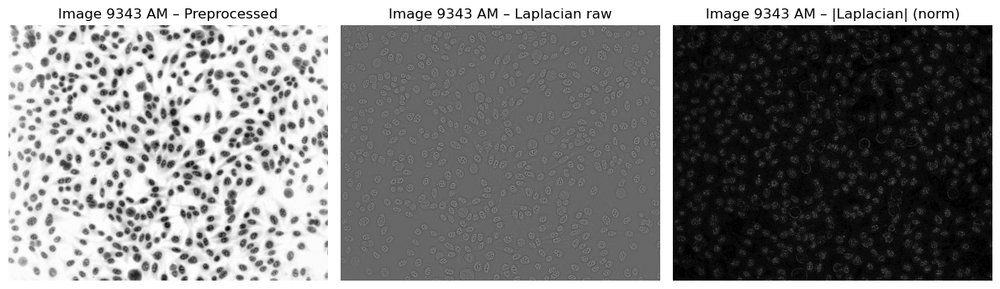

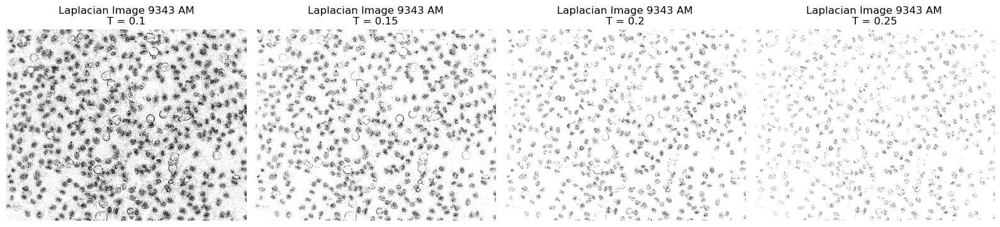

In [12]:
sobel_thresholds   = [0.15, 0.20, 0.25, 0.30]
prewitt_thresholds = [0.20, 0.25, 0.30, 0.35]
lap_thresholds     = [0.10, 0.15, 0.20, 0.25]

results_43590 = preprocess_image("Data 30213/cells/43590 AM.bmp", img_name="Image 43590 AM", show_plots=True)
sobel_mag_43590   = sobel_detector(results_43590, img_name="Image 43590 AM", thresholds = sobel_thresholds,   show_plots=True)
prewitt_mag_43590 = prewitt_detector(results_43590, img_name="Image 43590 AM", thresholds = prewitt_thresholds, show_plots=True)
lap_mag_43590    = laplacian_detector(results_43590, img_name="Image 43590 AM", thresholds = lap_thresholds, show_plots=True)

results_10905= preprocess_image("Data 30213/cells/10905 JL.bmp", img_name="Image 10905 JL", show_plots=True)
sobel_mag_10905   = sobel_detector(results_10905, img_name="Image 10905 JL", thresholds = sobel_thresholds,   show_plots=True)
prewitt_mag_10905 = prewitt_detector(results_10905, img_name="Image 10905 JL", thresholds = prewitt_thresholds, show_plots=True)
lap_mag_10905    = laplacian_detector(results_10905, img_name="Image 10905 JL", thresholds = lap_thresholds, show_plots=True)

results_9343 = preprocess_image("Data 30213/cells/9343 AM.bmp", img_name="Image 9343 AM", show_plots=True)
sobel_mag_9343   = sobel_detector(results_9343, img_name="Image 9343 AM", thresholds = sobel_thresholds,   show_plots=True)
prewitt_mag_9343= prewitt_detector(results_9343, img_name="Image 9343 AM", thresholds = prewitt_thresholds, show_plots=True)
lap_mag_9343     = laplacian_detector(results_9343, img_name="Image 9343 AM", thresholds = lap_thresholds, show_plots=True)


In [ ]:
# Thresholds used for Sobel
thresholds = lap_thresholds  

# Store image names and corresponding Sobel magnitudes
lap_images = [
    ("Image 43590 AM", lap_mag_43590),
    ("Image 10905 JL", lap_mag_10905),
    ("Image 9343 AM",  lap_mag_9343)
]

# Create a figure with rows = images, columns = thresholds
rows = len(lap_images)
cols = len(thresholds)

plt.figure(figsize=(4 * cols, 4 * rows))

for r, (img_name, mag) in enumerate(lap_images):
    for c, t in enumerate(thresholds):
        # Generate edge map
        edges_bw = binary_edges_from_mag(mag, t)

        # Plot location
        idx = r * cols + c + 1
        plt.subplot(rows, cols, idx)
        plt.imshow(edges_bw, cmap="gray", vmin=0, vmax=1)
        plt.title(f"{img_name}\nT = {t}")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
gt_43590_img, gt_43590_edges = load_gt_edges("Data 30213/cells/43590 AM Edges.bmp")
gt_10905_img, gt_10905_edges = load_gt_edges("Data 30213/cells/10905 JL Edges.bmp")
gt_9343_img, gt_9343_edges = load_gt_edges("Data 30213/cells/9343 AM Edges.bmp")

In [ ]:
# Sobel: find best threshold
best_T_sobel_43590, sobel_metrics_43590 = find_best_threshold(sobel_mag_43590, gt_43590_edges, sobel_thresholds, method_name="Sobel", img_name="Image 43590 AM")
best_T_sobel_10905, sobel_metrics_10905 = find_best_threshold(sobel_mag_10905, gt_10905_edges, sobel_thresholds, method_name="Sobel", img_name="Image 10905 JL")
best_T_sobel_9343, sobel_metrics_9343 = find_best_threshold(sobel_mag_9343, gt_9343_edges, sobel_thresholds, method_name="Sobel", img_name="Image 9343 AM")

# Prewitt: find best threshold
best_T_prewitt_43590, prewitt_metrics_43590 = find_best_threshold(prewitt_mag_43590, gt_43590_edges, prewitt_thresholds, method_name="Prewitt", img_name="Image 43590 AM")
best_T_prewitt_10905, prewitt_metrics_10905 = find_best_threshold(prewitt_mag_10905, gt_10905_edges, prewitt_thresholds, method_name="Prewitt", img_name="Image 10905 JL")
best_T_prewitt_9343, prewitt_metrics_9343 = find_best_threshold(prewitt_mag_9343, gt_9343_edges, prewitt_thresholds, method_name="Prewitt", img_name="Image 9343 AM")

# Laplacian: find best threshold
best_T_lap_43590, lap_metrics_43590 = find_best_threshold(lap_mag_43590, gt_43590_edges, lap_thresholds, method_name="Laplacian", img_name="Image 43590 AM")
best_T_lap_10905, lap_metrics_10905 = find_best_threshold(lap_mag_10905, gt_10905_edges, lap_thresholds, method_name="Laplacian", img_name="Image 10905 JL")
best_T_lap_9343, lap_metrics_9343 = find_best_threshold(lap_mag_9343, gt_9343_edges, lap_thresholds, method_name="Laplacian", img_name="Image 9343 AM")

Canny edge detector is a multi-stage edge detection algorithm. The image is first smoothed with a Gaussian filter to reduce noise, then the gradient magnitude and direction are computed.

In [ ]:
def find_best_canny(preprocessed_img, gt_edges,
                    low_vals=[0.05, 0.10, 0.15],
                    high_vals=[0.20, 0.30, 0.40],
                    sigma=1.0,
                    img_name=""):

    best_iou = -1.0
    best_low, best_high = None, None
    best_edges_bool = None
    best_metrics = None

    for low in low_vals:
        for high in high_vals:
            if high <= low:
                continue  # must have high > low

            edges_bool = canny(preprocessed_img,
                               sigma=sigma,
                               low_threshold=low,
                               high_threshold=high)

            iou  = compute_iou(gt_edges, edges_bool)
            dice = compute_dice(gt_edges, edges_bool)
            acc  = compute_accuracy(gt_edges, edges_bool)

            # print(f"{img_name}: low={low}, high={high} | IoU={iou:.4f}, Dice={dice:.4f}, Acc={acc:.4f}")

            if iou > best_iou:
                best_iou = iou
                best_low, best_high = low, high
                best_edges_bool = edges_bool
                best_metrics = {"IoU": iou, "Dice": dice, "Acc": acc}

    print(f"\nBest Canny for {img_name}: low={best_low}, high={best_high} (IoU={best_iou:.4f})\n")
    return best_low, best_high, best_edges_bool, best_metrics

In [ ]:
low_vals  = [0.05, 0.10, 0.15]
high_vals = [0.20, 0.30, 0.40]
sigma_canny = 1.0

# Image 43590
pre1 = preprocess_image("Data 30213/cells/43590 AM.bmp", sigma=1.0, clip_limit=0.01, show_plots=False, img_name="Image 43590")
best_low_43590, best_high_43590, canny_bool_43590, canny_metrics_43590 = find_best_canny(
    pre1, gt_43590_edges,
    low_vals=low_vals,
    high_vals=high_vals,
    sigma=sigma_canny,
    img_name="Image 43590 AM"
)

# Image 10905
pre2 = preprocess_image("Data 30213/cells/10905 JL.bmp", sigma=1.0, clip_limit=0.01, show_plots=True, img_name="Image 10905")
best_low_10905, best_high_10905, canny_bool_10905, canny_metrics_10905 = find_best_canny(
    pre2, gt_10905_edges,
    low_vals=low_vals,
    high_vals=high_vals,
    sigma=sigma_canny,
    img_name="Image 10905 JL"
)

# Image 9343
pre3 = preprocess_image("Data 30213/cells/9343 AM.bmp", sigma=1.0, clip_limit=0.01, show_plots=True, img_name="Image 9343")

best_low_9343, best_high_9343, canny_bool_9343, canny_metrics_9343 = find_best_canny(
    pre3, gt_9343_edges,
    low_vals=low_vals,
    high_vals=high_vals,
    sigma=sigma_canny,
    img_name="Image 9343 AM"
)

In [ ]:
def bool_to_bw(edges_bool):
    return np.where(edges_bool, 0.0, 1.0)  # 0=black edges, 1=white bg

edges_bw_43590 = bool_to_bw(canny_bool_43590)
edges_bw_10905 = bool_to_bw(canny_bool_10905)
edges_bw_9343  = bool_to_bw(canny_bool_9343)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(edges_bw_43590, cmap="gray", vmin=0, vmax=1)
plt.title(f"43590 AM– Canny (low={best_low_43590}, high={best_high_43590})")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(edges_bw_10905, cmap="gray", vmin=0, vmax=1)
plt.title(f"10905 JL– Canny (low={best_low_10905}, high={best_high_10905})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges_bw_9343, cmap="gray", vmin=0, vmax=1)
plt.title(f"9343 AM– Canny (low={best_low_9343}, high={best_high_9343})")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Build binary edge images for best thresholds
sobel_edges_43590   = binary_edges_from_mag(sobel_mag_43590,   0.20)
prewitt_edges_43590 = binary_edges_from_mag(prewitt_mag_43590, 0.2)
lap_edges_43590     = binary_edges_from_mag(lap_mag_43590,    0.1)

# Canny: convert boolean to 0/1
canny_edges_43590 = bool_to_bw(canny_bool_43590)

plt.figure(figsize=(16, 4))

plt.subplot(1, 5, 1)
plt.imshow(pre1, cmap="gray")
plt.title("Preprocessed")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(sobel_edges_43590, cmap="gray", vmin=0, vmax=1)
plt.title(f"Sobel (T={0.2})")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(prewitt_edges_43590, cmap="gray", vmin=0, vmax=1)
plt.title(f"Prewitt (T={0.2})")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(lap_edges_43590, cmap="gray", vmin=0, vmax=1)
plt.title(f"Laplacian (T={0.1})")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(canny_edges_43590, cmap="gray", vmin=0, vmax=1)
plt.title("Canny (best low/high)")
plt.axis("off")

plt.tight_layout()
plt.show()

Hough Transform 

In [ ]:
bham_rgb = io.imread("Data 30213/Bhamimage.jpeg")  

# Convert to grayscale (float in [0,1])
bham_gray = color.rgb2gray(bham_rgb)

print("Original shape:", bham_rgb.shape)
print("Grayscale shape:", bham_gray.shape)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(bham_rgb)
plt.title("Original Bhamimage")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(bham_gray, cmap="gray")
plt.title("Grayscale Bhamimage")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Canny edge detection
edges_bham = canny(
    bham_gray,
    sigma=2.0,          # smoothing inside Canny
    low_threshold=0.1,  # tweak if too noisy
    high_threshold=0.3  # tweak if edges are too weak
)

plt.figure(figsize=(6, 6))
plt.imshow(edges_bham, cmap="gray")
plt.title("Canny edges – Bhamimage")
plt.axis("off")
plt.show()

In [ ]:
hspace, angles, dists = hough_line(edges_bham)

# --- Extract strongest straight-line peaks ---
accums, thetas, rhos = hough_line_peaks(
    hspace,
    angles,
    dists,
    num_peaks=10      # how many straight lines to detect
)

# Print detected straight-line parameters
print("Detected straight-line parameters (rho, theta):")
plt.figure(figsize=(8, 8))
plt.imshow(bham_rgb)
plt.title("Detected Straight Lines (Hough Transform)")
plt.axis("off")

height, width = bham_rgb.shape[:2]

for rho, theta in zip(rhos, thetas):
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho

    # Compute line across full image width
    x1 = 0
    y1 = (rho - x1 * a) / b

    x2 = width
    y2 = (rho - x2 * a) / b

    plt.plot([x1, x2], [y1, y2], '-r', linewidth=2)

# VERY IMPORTANT: fix axes so image isn't shrunk
plt.xlim([0, width])
plt.ylim([height, 0])  # flip y-axis for image coordinates

plt.show()

In [ ]:

# Load image and convert to grayscale
img_rgb = skimage.io.imread("Data 30213/Bhamimage.jpeg")       
img_gray = color.rgb2gray(img_rgb)

# Canny edge detection (edge map)
edges = canny(img_gray, sigma=2.0,
              low_threshold=0.1,
              high_threshold=0.3)

# Straight-line Hough transform
hspace, angles, dists = hough_line(edges)

# Extract most prominent lines
accums, thetas, rhos = hough_line_peaks(
    hspace, angles, dists,
    num_peaks=10  # number of strongest lines to keep
)

# === Plot 1: Canny edge map ===
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(edges, cmap="gray")
plt.title("Edge map (Canny)")
plt.axis("off")

# === Plot 2: Hough accumulator ===
# Convert angles to degrees for nicer axis labels
angle_degrees = np.rad2deg(angles)

plt.subplot(1, 3, 2)
plt.imshow(
    hspace,
    cmap="gray",
    extent=[angle_degrees[-1], angle_degrees[0], dists[-1], dists[0]],
    aspect='auto'
)
plt.title("Hough accumulator")
plt.xlabel("Angle (degrees)")
plt.ylabel("Distance (pixels)")
plt.colorbar(label="Votes")

